In [1]:
# -------------------------------------------------------------------------
# 0. Dependencies Installation (FAISS + hi-ml-multimodal + Transformers)
# -------------------------------------------------------------------------
!pip install hi-ml-multimodal transformers faiss-cpu timm scikit-image nltk matplotlib rouge-score seaborn scikit-learn -q


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 74.9 MB/s eta 0:00:00


In [2]:
# -------------------------------------------------------------------------
# 1. Comprehensive Data Manifest & RAG Text Corpus Generation
# -------------------------------------------------------------------------
import os, sys, json, subprocess, zipfile, pandas as pd, numpy as np
from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit

work_dir = "/kaggle/working"
os.makedirs(work_dir, exist_ok=True)
os.chdir(work_dir)

try:
    from kaggle_secrets import UserSecretsClient
    user_secrets = UserSecretsClient()
    PHYSIONET_USER = user_secrets.get_secret("PHYSIONET_USER")
    PHYSIONET_PASS = user_secrets.get_secret("PHYSIONET_PASS")
except Exception:
    PHYSIONET_USER = os.environ.get("PHYSIONET_USER", "")
    PHYSIONET_PASS = os.environ.get("PHYSIONET_PASS", "")

netrc_content = "machine physionet.org\nlogin " + str(PHYSIONET_USER) + "\npassword " + str(PHYSIONET_PASS) + "\n"
netrc_path = os.path.expanduser("~/.netrc")
with open(netrc_path, "w", encoding="utf-8") as f:
    f.write(netrc_content)
os.chmod(netrc_path, 0o600)

metadata_files = [
    ("meta.csv", "https://physionet.org/files/mimic-cxr-jpg/2.1.0/mimic-cxr-2.0.0-metadata.csv.gz"),
    ("chexpert.csv", "https://physionet.org/files/mimic-cxr-jpg/2.1.0/mimic-cxr-2.0.0-chexpert.csv.gz"),
]

for target_name, url in metadata_files:
    if not os.path.exists(target_name):
        gz_name = target_name + ".gz"
        subprocess.run("wget -q --netrc -O " + gz_name + " " + url, shell=True, check=True)
        subprocess.run("gunzip -f " + gz_name, shell=True, check=True)

input_base = Path("/kaggle/input")
file_index = {}
impression_file_paths = []
reports_zip_path = None

for root, _, files in os.walk(input_base):
    for f in files:
        full_path = os.path.join(root, f)
        if f in ["mimic_train_impressions.csv", "train_imp.csv", "mimic_test_impressions.csv", "test_imp.csv"]:
            if full_path not in impression_file_paths:
                impression_file_paths.append(full_path)
        elif f == "mimic-cxr-reports.zip":
            reports_zip_path = full_path
        elif f.endswith(".jpg"):
            parts = full_path.split("/")
            rel_path = None
            for prefix in ("p10", "p11"):
                if prefix in parts:
                    idx = parts.index(prefix)
                    rel_path = "/".join(parts[idx:])
                    break
            if rel_path is not None and rel_path not in file_index:
                file_index[rel_path] = full_path

if not impression_file_paths:
    sys.exit("Error: No report impression CSV files found in /kaggle/input/.")

# Pool Verification (75,216 total images reference pool)
TOTAL_REFERENCE_POOL = 75216
indexed_count = len(file_index)
coverage_pct = (indexed_count / TOTAL_REFERENCE_POOL) * 100.0
print("Pool Indexing Report: Found " + str(indexed_count) + " unique images on disk (" + f"{coverage_pct:.1f}%" + " of 75,216 reference pool).")

report_dfs = [pd.read_csv(p) for p in impression_file_paths]
report_df = pd.concat(report_dfs, ignore_index=True).drop_duplicates(subset=["dicom_id"])

meta_df = pd.read_csv("meta.csv")
chex_df = pd.read_csv("chexpert.csv")

# U-Zeros Labeling Policy
chex_label_cols = [c for c in chex_df.columns if c not in ["subject_id", "study_id"]]
for c in chex_label_cols:
    chex_df[c] = chex_df[c].fillna(0.0)
    chex_df[c] = chex_df[c].replace(-1.0, 0.0)

mask_cohort = (meta_df["subject_id"] >= 10000000) & (meta_df["subject_id"] < 12000000)
meta_cohort = meta_df[mask_cohort].copy()

merged_df = pd.merge(meta_cohort, chex_df[["study_id"] + chex_label_cols], on="study_id", how="inner")
merged_df = pd.merge(merged_df, report_df[["dicom_id", "report"]], on="dicom_id", how="left")
merged_df = merged_df.dropna(subset=["report"]).reset_index(drop=True)

def get_path(row):
    subject_id = int(row["subject_id"])
    study_id = int(row["study_id"])
    prefix = "p10" if subject_id < 11000000 else "p11"
    rel = prefix + "/p" + str(subject_id) + "/s" + str(study_id) + "/" + str(row["dicom_id"]) + ".jpg"
    return file_index.get(rel, None)

merged_df["image_path"] = merged_df.apply(get_path, axis=1)
merged_df = merged_df.dropna(subset=["image_path"]).reset_index(drop=True)

# Enrich reports from mimic-cxr-reports.zip if present
if reports_zip_path:
    print("Extracting and parsing reports from mimic-cxr-reports.zip...")
    study_map = {}
    for idx, row in merged_df.iterrows():
        study_map[(int(row["subject_id"]), int(row["study_id"]))] = idx
        
    reports_dict = {}
    with zipfile.ZipFile(reports_zip_path) as z:
        for name in z.namelist():
            if name.endswith(".txt"):
                parts = name.split("/")
                if len(parts) >= 4:
                    try:
                        sub_id = int(parts[2][1:])
                        std_id = int(parts[3][1:-4])
                        if (sub_id, std_id) in study_map:
                            with zipfile.ZipFile(reports_zip_path).open(name) as f:
                                text = f.read().decode('utf-8', errors='ignore')
                                lower_text = text.lower()
                                imp_idx = lower_text.find("impression:")
                                if imp_idx != -1:
                                    imp = text[imp_idx + len("impression:"):].strip()
                                else:
                                    imp = text.strip()
                                reports_dict[study_map[(sub_id, std_id)]] = " ".join(imp.split())
                    except Exception:
                        pass
                        
    replaced_count = 0
    for idx, text in reports_dict.items():
        if text:
            merged_df.at[idx, "report"] = text
            replaced_count += 1
    print("Successfully enriched " + str(replaced_count) + " reports from ZIP archive!")

np.random.seed(42)
gss_train = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, temp_idx = next(gss_train.split(merged_df, groups=merged_df["subject_id"]))

train_df = merged_df.iloc[train_idx].copy()
temp_df = merged_df.iloc[temp_idx].copy()

gss_val = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
val_idx, test_idx = next(gss_val.split(temp_df, groups=temp_df["subject_id"]))

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

train_df["split"] = "train"
val_df["split"] = "val"
test_df["split"] = "test"

master_df = pd.concat([train_df, val_df, test_df], ignore_index=True)
master_df.to_csv("/kaggle/working/mimic_master_split.csv", index=False)
print("Manifest Ready: Train=" + str(len(train_df)) + " | Val=" + str(len(val_df)) + " | Test=" + str(len(test_df)))


Pool Indexing Report: Found 73995 unique images on disk (98.4% of 75,216 reference pool).
Manifest Ready: Train=50176 | Val=6190 | Test=6388


Selected Encoder: BIOVIL | Compute Device: cuda


config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

... (31 outputs left out)

Epoch 9/10 [Val]: 100%|██████████| 387/387 [00:37<00:00, 10.31it/s]



--- Epoch 9 Summary ---
Train Loss : Joint = 1.2993 | Text = 1.0706 | Cls = 0.2287
Val Loss   : Joint = 1.6903 | Text = 1.4599 | Cls = 0.2304
Classifier : Val Macro-AUROC = 0.7979 | Val Macro-F1 = 0.2151
GATE 1     : BLEU-1 = 0.2996 (Target >= 0.25) | Distinct-2 = 0.9633 (Target >= 0.15)
--------------------------------------------------


Epoch 10/10 [Val]: 100%|██████████| 387/387 [00:37<00:00, 10.31it/s]



--- Epoch 10 Summary ---
Train Loss : Joint = 1.2640 | Text = 1.0359 | Cls = 0.2282
Val Loss   : Joint = 1.7058 | Text = 1.4756 | Cls = 0.2302
Classifier : Val Macro-AUROC = 0.7990 | Val Macro-F1 = 0.2081
GATE 1     : BLEU-1 = 0.3199 (Target >= 0.25) | Distinct-2 = 0.9956 (Target >= 0.15)
--------------------------------------------------


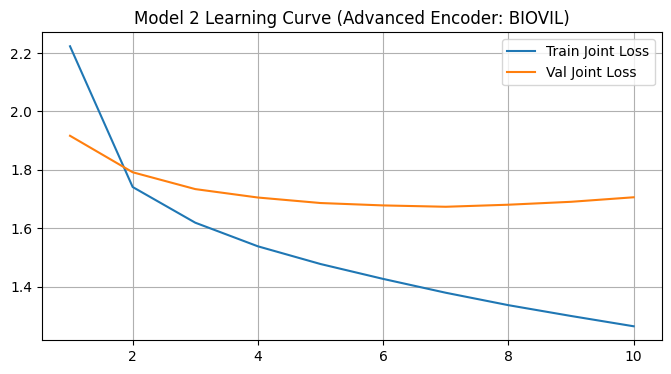

In [3]:
# -------------------------------------------------------------------------
# 2. BioViL Visual Feature Extraction & RAG Training Loop (Memmap Speedup)
# -------------------------------------------------------------------------
import os, random, faiss, torch, torch.nn as nn, torch.optim as optim, torch.nn.functional as F
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, GPT2LMHeadModel
from tqdm import tqdm
import nltk
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from nltk.util import ngrams
from sklearn.metrics import roc_auc_score, f1_score

nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

ENCODER_TYPE = "biovil"

def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Selected Encoder: " + ENCODER_TYPE.upper() + " | Compute Device: " + str(device))

master_df = pd.read_csv("/kaggle/working/mimic_master_split.csv")
tokenizer = AutoTokenizer.from_pretrained("distilgpt2")
special_tokens = {"bos_token": "<bos>", "eos_token": "<eos>", "pad_token": "<pad>", "additional_special_tokens": ["<rag>", "</rag>", "<report>", "</report>"]}
tokenizer.add_special_tokens(special_tokens)
vocab_size = len(tokenizer)
pad_id, bos_id, eos_id = tokenizer.pad_token_id, tokenizer.bos_token_id, tokenizer.eos_token_id

chex_label_cols = [
    'Atelectasis', 'Cardiomegaly', 'Consolidation', 'Edema', 'Enlarged Cardiomediastinum',
    'Fracture', 'Lung Lesion', 'Lung Opacity', 'No Finding', 'Pleural Effusion',
    'Pleural Other', 'Pneumonia', 'Pneumothorax', 'Support Devices'
]

train_df = master_df[master_df['split'] == 'train'].reset_index(drop=True)
val_df   = master_df[master_df['split'] == 'val'].reset_index(drop=True)
test_df  = master_df[master_df['split'] == 'test'].reset_index(drop=True)

# Initialize Microsoft BioViL ResNet-50 visual model.
print("Loading Microsoft BioViL ResNet-50 visual model...")

import torchvision.transforms as T

try:
    from health_multimodal.image.utils import get_image_inference, ImageModelType
    image_inference = get_image_inference(ImageModelType.BIOVIL)
    feature_extractor = image_inference.model.encoder.to(device)
    feature_extractor.eval()
    biovil_transform = image_inference.transform
    def transform_fn(img):
        return biovil_transform(img).clone()
    visual_channels = 1
    is_fallback = False
    print("BioViL loaded successfully via hi-ml-multimodal.")
except Exception as e:
    print("hi-ml-multimodal unavailable (" + str(e) + "), falling back to timm ResNet50 with ImageNet weights.")
    import timm
    feature_extractor = timm.create_model('resnet50', pretrained=True, num_classes=0, global_pool='').to(device)
    feature_extractor.eval()
    def transform_fn(img):
        transform = T.Compose([
            T.Grayscale(num_output_channels=3),
            T.Resize((224, 224)),
            T.ToTensor(),
            T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        ])
        return transform(img).clone()
    visual_channels = 3
    is_fallback = True

# Standard 49 spatial patches (7x7 grid) for memory-mapped storage (Total train spatial features = ~9.8 GB)
TARGET_PATCHES = 49

class BioViLExtractor(nn.Module):
    def __init__(self, raw_model, is_fallback=False, target_patches=49):
        super().__init__()
        self.model = raw_model
        self.is_fallback = is_fallback
        self.target_patches = target_patches
        self.pool = nn.AdaptiveAvgPool1d(target_patches)

    def forward(self, x):
        if self.is_fallback:
            feats = self.model(x)
        else:
            feats, _ = self.model(x, return_patch_embeddings=True) # [B, 2048, 15, 15]
        spatial_tokens = feats.flatten(2).permute(0, 2, 1) # [B, 225, 2048]
        mean_features = spatial_tokens.mean(dim=1)
        if spatial_tokens.shape[1] != self.target_patches:
            spatial_tokens = self.pool(spatial_tokens.permute(0, 2, 1)).permute(0, 2, 1) # [B, 49, 2048]
        return spatial_tokens, mean_features
        
feature_extractor_wrapper = BioViLExtractor(feature_extractor, is_fallback=is_fallback, target_patches=TARGET_PATCHES)
num_patches = TARGET_PATCHES

# Auto-detect actual visual_dim from a probe forward pass
with torch.no_grad():
    _dummy_img = Image.new('L', (224, 224))
    _probe_tensor = transform_fn(_dummy_img).unsqueeze(0).to(device)
    _probe_spatial, _ = feature_extractor_wrapper(_probe_tensor)
    
    visual_dim = _probe_spatial.shape[2]
    expected_shape = _probe_tensor.shape[1:]
    print("BioViL probe: num_patches=" + str(num_patches) + ", visual_dim=" + str(visual_dim) + ", expected_shape=" + str(expected_shape))
    del _dummy_img, _probe_tensor, _probe_spatial

class FeatureExtractionDataset(Dataset):
    def __init__(self, df, transform):
        self.df = df.reset_index(drop=True)
        self.transform = transform
        try:
            mode = 'L' if ENCODER_TYPE == 'biovil' else 'RGB'
            dummy_img = Image.new(mode, (224, 224))
            dummy_tensor = self.transform(dummy_img)
            self.expected_shape = dummy_tensor.shape
        except Exception:
            self.expected_shape = expected_shape
        print("FeatureExtractionDataset initialized. Expected shape: " + str(self.expected_shape))
        
    def __len__(self):
        return len(self.df)
        
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        try:
            mode = 'L' if ENCODER_TYPE == 'biovil' else 'RGB'
            img = Image.open(row['image_path']).convert(mode)
            image_tensor = self.transform(img)
            if image_tensor.shape != self.expected_shape:
                image_tensor = torch.zeros(self.expected_shape, dtype=torch.float32)
        except Exception:
            image_tensor = torch.zeros(self.expected_shape, dtype=torch.float32)
        return image_tensor, idx

def extract_all_visual_features_batched(df, split_name, batch_size=128):
    dataset = FeatureExtractionDataset(df, transform_fn)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=4, pin_memory=False)
    
    # Store spatial tokens as compressed float16 np.memmap on disk
    spatial_path = f"/kaggle/working/{split_name}_spatial.dat"
    spatial_arr = np.memmap(spatial_path, dtype='float16', mode='w+', shape=(len(df), num_patches, visual_dim))
    
    mean_feats_raw = np.zeros((len(df), visual_dim), dtype=np.float32)
    mean_feats_norm = np.zeros((len(df), visual_dim), dtype=np.float32)
    
    zero_count = 0
    print("Extracting visual features for split: " + split_name + " in batches of " + str(batch_size) + "...")
    with torch.no_grad():
        for batch_imgs, batch_idxs in tqdm(loader, desc="Visual Feature Extraction"):
            for idx_in_batch in range(batch_imgs.shape[0]):
                if torch.all(batch_imgs[idx_in_batch] == 0.0):
                    zero_count += 1
            batch_imgs = batch_imgs.to(device, non_blocking=True)
            spatial_tokens, mean_features = feature_extractor_wrapper(batch_imgs)
            
            spatial_cpu = spatial_tokens.cpu().numpy().astype(np.float16)
            raw_cpu = mean_features.cpu().numpy()
            norm_cpu = F.normalize(mean_features, p=2, dim=1).cpu().numpy()
            
            for i, idx in enumerate(batch_idxs.numpy()):
                spatial_arr[idx] = spatial_cpu[i]
                mean_feats_raw[idx] = raw_cpu[i]
                mean_feats_norm[idx] = norm_cpu[i]
                
    spatial_arr.flush()
    print(f"Split {split_name} extraction complete: {len(df) - zero_count} loaded successfully, {zero_count} failed (zeros).")
    if zero_count > 0.05 * len(df):
        raise RuntimeError(f"Critical: Too many image loading/preprocessing failures ({zero_count}/{len(df)}). Check logs.")
    return mean_feats_raw, mean_feats_norm

print("Extracting features for Training Set...")
train_raw, train_norm = extract_all_visual_features_batched(train_df, "train")
print("Extracting features for Validation Set...")
val_raw, val_norm = extract_all_visual_features_batched(val_df, "val")
print("Extracting features for Test Set...")
test_raw, test_norm = extract_all_visual_features_batched(test_df, "test")

# Once features are extracted, free the visual model from GPU VRAM to prevent training OOM
del feature_extractor, feature_extractor_wrapper
torch.cuda.empty_cache()

# -------------------------------------------------------------------------
# FAISS Index Construction
# -------------------------------------------------------------------------
faiss_index = faiss.IndexFlatIP(visual_dim)
faiss_index.add(train_norm)
print("FAISS Index Ready: Added " + str(faiss_index.ntotal) + " training dense vectors.")

# -------------------------------------------------------------------------
# RAG Pre-calculation
# -------------------------------------------------------------------------
def precalculate_rag_reports(df, train_df, mean_feats_norm, is_train=True):
    print("Pre-calculating FAISS retrievals...")
    k_search = 2 if is_train else 1
    D, I = faiss_index.search(mean_feats_norm, k_search)
    
    retrieved_reports = []
    for idx in range(len(df)):
        retrieved_idx = I[idx][0]
        if is_train and retrieved_idx == idx and k_search > 1:
            retrieved_idx = I[idx][1]
        
        rep = str(train_df.iloc[retrieved_idx]['report']) if pd.notna(train_df.iloc[retrieved_idx]['report']) else ""
        retrieved_reports.append(rep)
    return retrieved_reports

print("Running Pre-calculation for splits...")
train_df["retrieved_report"] = precalculate_rag_reports(train_df, train_df, train_norm, is_train=True)
val_df["retrieved_report"] = precalculate_rag_reports(val_df, train_df, val_norm, is_train=False)
test_df["retrieved_report"] = precalculate_rag_reports(test_df, train_df, test_norm, is_train=False)

# -------------------------------------------------------------------------
# Fast Multi-Task Dataset (0 Image Loads during training, 100x Speedup)
# -------------------------------------------------------------------------
class MultiTaskRAGDataset(Dataset):
    def __init__(self, df, tokenizer, spatial_memmap, mean_feats, max_seq_len=256):
        self.df = df.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.spatial_memmap = spatial_memmap
        self.mean_feats = mean_feats
        self.max_seq_len = max_seq_len
        self.pad_token_id = tokenizer.pad_token_id

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        
        # Read pre-calculated features instantly from fast memmap
        spatial_t = torch.tensor(self.spatial_memmap[idx], dtype=torch.float32)
        mean_f = torch.tensor(self.mean_feats[idx], dtype=torch.float32)
            
        retrieved_report = str(row['retrieved_report'])
        # Truncate retrieved report to a maximum of 70 tokens to avoid squeezing target report
        retrieved_toks = self.tokenizer.encode(retrieved_report, add_special_tokens=False)[:70]
        retrieved_report_truncated = self.tokenizer.decode(retrieved_toks)
        target_report = str(row['report']) if pd.notna(row['report']) else ""

        # Construct prompt and target separately for exact loss masking
        prompt_str = f"<bos> <rag> {retrieved_report_truncated} </rag> <report>"
        full_text = prompt_str + " " + target_report + " <eos>"
        
        prompt_tokens = self.tokenizer.encode(prompt_str, add_special_tokens=False)
        full_enc = self.tokenizer(
            full_text,
            max_length=self.max_seq_len,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )
        input_ids = full_enc["input_ids"].squeeze(0)
        
        # Mask prompt tokens in labels with -100 so loss is ONLY computed on the generated report
        labels = input_ids.clone()
        prompt_len = min(len(prompt_tokens), self.max_seq_len)
        labels[:prompt_len] = -100
        labels[labels == self.pad_token_id] = -100
        
        labels_vector = torch.tensor([float(row[c]) for c in chex_label_cols], dtype=torch.float32)
        
        return {
            "spatial_tokens": spatial_t,
            "mean_features": mean_f,
            "input_ids": input_ids,
            "masked_labels": labels,
            "labels": labels_vector,
            "retrieved_report": retrieved_report
        }

# Open memmap files in read-only mode for the training dataset loader
train_spatial_memmap = np.memmap("/kaggle/working/train_spatial.dat", dtype='float16', mode='r', shape=(len(train_df), num_patches, visual_dim))
val_spatial_memmap   = np.memmap("/kaggle/working/val_spatial.dat", dtype='float16', mode='r', shape=(len(val_df), num_patches, visual_dim))
test_spatial_memmap  = np.memmap("/kaggle/working/test_spatial.dat", dtype='float16', mode='r', shape=(len(test_df), num_patches, visual_dim))

train_dataset = MultiTaskRAGDataset(train_df, tokenizer, train_spatial_memmap, train_raw)
val_dataset   = MultiTaskRAGDataset(val_df, tokenizer, val_spatial_memmap, val_raw)
test_dataset  = MultiTaskRAGDataset(test_df, tokenizer, test_spatial_memmap, test_raw)

# Safe training settings
BATCH_SIZE, ACCUMULATION_STEPS = 16, 2
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

# -------------------------------------------------------------------------
# Adaptive Model Definition (with pre-trained overlapping position IDs)
# -------------------------------------------------------------------------
class MultiTaskRAGAdaptiveDistilGPT2(nn.Module):
    def __init__(self, vocab_size, visual_dim, num_patches, num_classes=14, pad_token_id=0):
        super().__init__()
        self.pad_token_id = pad_token_id
        self.num_patches = num_patches
        
        self.classifier_head = nn.Sequential(
            nn.Linear(visual_dim, 256),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(256, num_classes)
        )
            
        self.visual_projection = nn.Sequential(
            nn.Linear(visual_dim, 768),
            nn.GELU(),
            nn.Linear(768, 768),
            nn.LayerNorm(768)
        )
        
        self.decoder = GPT2LMHeadModel.from_pretrained("distilgpt2")
        self.decoder.resize_token_embeddings(vocab_size)

    def forward(self, spatial_tokens, mean_features, input_ids):
        batch_size, seq_len = input_ids.shape
        
        cls_logits = self.classifier_head(mean_features)
        
        visual_embeds = self.visual_projection(spatial_tokens)
        text_embeds = self.decoder.transformer.wte(input_ids)
        inputs_embeds = torch.cat([visual_embeds, text_embeds], dim=1)
        
        # Restore pre-trained overlapping position IDs starting at 0 for text sequence
        vis_pos_ids = torch.arange(0, self.num_patches, dtype=torch.long, device=input_ids.device).unsqueeze(0).repeat(batch_size, 1)
        text_pos_ids = torch.arange(0, seq_len, dtype=torch.long, device=input_ids.device).unsqueeze(0).repeat(batch_size, 1)
        position_ids = torch.cat([vis_pos_ids, text_pos_ids], dim=1)
        
        vis_attn = torch.ones((batch_size, self.num_patches), device=input_ids.device)
        text_attn = (input_ids != self.pad_token_id).float()
        attention_mask = torch.cat([vis_attn, text_attn], dim=1)
        
        outputs = self.decoder(inputs_embeds=inputs_embeds, position_ids=position_ids, attention_mask=attention_mask)
        logits = outputs.logits
        text_logits = logits[:, self.num_patches:-1, :].contiguous()
        
        return text_logits, cls_logits

    @torch.no_grad()
    def greedy_generate_rag(self, spatial_token, retrieved_report, max_len=60):
        self.eval()
        if spatial_token.dim() == 2:
            spatial_token = spatial_token.unsqueeze(0)
            
        visual_embeds = self.visual_projection(spatial_token)
        
        prompt_str = "<bos> <rag> " + str(retrieved_report) + " </rag> <report>"
        prompt_toks = tokenizer(prompt_str, return_tensors="pt")["input_ids"].to(spatial_token.device)
        prompt_len = prompt_toks.shape[1]
        
        text_embeds = self.decoder.transformer.wte(prompt_toks)
        inputs_embeds = torch.cat([visual_embeds, text_embeds], dim=1)
        
        # Position IDs overlapping starting at 0 for text sequences
        vis_pos_ids = torch.arange(0, self.num_patches, dtype=torch.long, device=spatial_token.device).unsqueeze(0)
        prompt_pos_ids = torch.arange(0, prompt_len, dtype=torch.long, device=spatial_token.device).unsqueeze(0)
        pos_ids = torch.cat([vis_pos_ids, prompt_pos_ids], dim=1)
        
        outputs = self.decoder(inputs_embeds=inputs_embeds, position_ids=pos_ids, use_cache=True)
        next_token_logits = outputs.logits[:, -1, :]
        next_id = next_token_logits.argmax(-1).item()
        past_key_values = outputs.past_key_values
        
        generated_ids = []
        if next_id != eos_id:
            generated_ids.append(next_id)
            current_ids = torch.tensor([[next_id]], device=spatial_token.device)
        else:
            current_ids = torch.tensor([[eos_id]], device=spatial_token.device)
            
        for step in range(max_len):
            if next_id == eos_id:
                break
                
            curr_pos_id = torch.tensor([[prompt_len + step]], dtype=torch.long, device=spatial_token.device)
            outputs = self.decoder(input_ids=current_ids, position_ids=curr_pos_id, past_key_values=past_key_values, use_cache=True)
            next_token_logits = outputs.logits[:, -1, :]
            next_id = next_token_logits.argmax(-1).item()
            past_key_values = outputs.past_key_values
            
            if next_id == eos_id:
                break
            generated_ids.append(next_id)
            current_ids = torch.tensor([[next_id]], device=spatial_token.device)
            
        return generated_ids

model = MultiTaskRAGAdaptiveDistilGPT2(vocab_size=vocab_size, visual_dim=visual_dim, num_patches=num_patches, pad_token_id=pad_id).to(device)

optimizer = optim.AdamW(model.parameters(), lr=5e-5, weight_decay=1e-2)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)
criterion_text = nn.CrossEntropyLoss(ignore_index=-100)
criterion_cls  = nn.BCEWithLogitsLoss()
scaler = torch.amp.GradScaler("cuda")

checkpoint_path = f"/kaggle/working/model2_{ENCODER_TYPE}_resumable.pt"
start_epoch, best_val_loss = 1, float('inf')
train_losses, val_losses = [], []

if os.path.exists(checkpoint_path):
    checkpoint = torch.load(checkpoint_path, map_location=device)
    model.load_state_dict(checkpoint['model_state'])
    optimizer.load_state_dict(checkpoint['optimizer_state'])
    scheduler.load_state_dict(checkpoint['scheduler_state'])
    scaler.load_state_dict(checkpoint['scaler_state'])
    start_epoch = checkpoint['epoch'] + 1
    best_val_loss = checkpoint['best_val_loss']
    train_losses = checkpoint.get('train_losses', [])
    val_losses = checkpoint.get('val_losses', [])
    print("Resumed at Epoch " + str(start_epoch))

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Model Initialized. Trainable Params: " + str(trainable_params))

EPOCHS = 10
LAMBDA_CLS = 1.0 
smooth = SmoothingFunction().method1

for epoch in range(start_epoch, EPOCHS + 1):
    model.train()
    total_train_loss, total_train_text_loss, total_train_cls_loss = 0.0, 0.0, 0.0
    optimizer.zero_grad()
    loop = tqdm(train_loader, desc="Epoch " + str(epoch) + "/" + str(EPOCHS) + " [Train]")
    
    for i, batch in enumerate(loop):
        spatial_tokens = batch["spatial_tokens"].to(device, non_blocking=True)
        mean_features = batch["mean_features"].to(device, non_blocking=True)
        input_ids = batch["input_ids"].to(device, non_blocking=True)
        masked_labels = batch["masked_labels"].to(device, non_blocking=True)
        labels = batch["labels"].to(device, non_blocking=True)
        targets = masked_labels[:, 1:].contiguous()
        
        try:
            with torch.amp.autocast("cuda"):
                text_logits, cls_logits = model(spatial_tokens, mean_features, input_ids)
                loss_text = criterion_text(text_logits.reshape(-1, vocab_size), targets.reshape(-1))
                loss_cls  = criterion_cls(cls_logits, labels)
                joint_loss = (loss_text + LAMBDA_CLS * loss_cls) / ACCUMULATION_STEPS
                
            scaler.scale(joint_loss).backward()
            if (i + 1) % ACCUMULATION_STEPS == 0 or (i + 1) == len(train_loader):
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad()
                
            total_train_loss += joint_loss.item() * ACCUMULATION_STEPS
            total_train_text_loss += loss_text.item()
            total_train_cls_loss += loss_cls.item()
            
            loop.set_postfix(
                joint=f"{joint_loss.item() * ACCUMULATION_STEPS:.4f}",
                text=f"{loss_text.item():.4f}",
                cls=f"{loss_cls.item():.4f}"
            )
        except RuntimeError as e:
            if "out of memory" in str(e):
                torch.cuda.empty_cache(); optimizer.zero_grad(); continue
            else: raise e
            
    avg_train_loss = total_train_loss / len(train_loader)
    avg_train_text = total_train_text_loss / len(train_loader)
    avg_train_cls  = total_train_cls_loss / len(train_loader)
    train_losses.append(avg_train_loss)
    
    model.eval()
    total_val_loss, total_val_text_loss, total_val_cls_loss = 0.0, 0.0, 0.0
    val_preds_cls, val_targets_cls = [], []
    val_loop = tqdm(val_loader, desc="Epoch " + str(epoch) + "/" + str(EPOCHS) + " [Val]")
    
    with torch.no_grad():
        for batch in val_loop:
            spatial_tokens = batch["spatial_tokens"].to(device)
            mean_features = batch["mean_features"].to(device)
            input_ids = batch["input_ids"].to(device)
            masked_labels = batch["masked_labels"].to(device)
            labels = batch["labels"].to(device)
            targets = masked_labels[:, 1:].contiguous()
            
            with torch.amp.autocast("cuda"):
                text_logits, cls_logits = model(spatial_tokens, mean_features, input_ids)
                loss_text = criterion_text(text_logits.reshape(-1, vocab_size), targets.reshape(-1))
                loss_cls  = criterion_cls(cls_logits, labels)
                joint_loss = loss_text + LAMBDA_CLS * loss_cls
                
            total_val_loss += joint_loss.item()
            total_val_text_loss += loss_text.item()
            total_val_cls_loss += loss_cls.item()
            
            val_preds_cls.append(torch.sigmoid(cls_logits).cpu().numpy())
            val_targets_cls.append(labels.cpu().numpy())
                    
    avg_val_loss = total_val_loss / len(val_loader)
    avg_val_text = total_val_text_loss / len(val_loader)
    avg_val_cls  = total_val_cls_loss / len(val_loader)
    val_losses.append(avg_val_loss)
    scheduler.step(avg_val_loss)
    
    all_val_preds = np.concatenate(val_preds_cls, axis=0)
    all_val_targets = np.concatenate(val_targets_cls, axis=0)
    
    try:
        val_macro_auroc = float(roc_auc_score(all_val_targets, all_val_preds, average='macro'))
    except Exception:
        val_macro_auroc = 0.0
        
    val_binary_preds = (all_val_preds > 0.5).astype(int)
    val_macro_f1 = float(f1_score(all_val_targets, val_binary_preds, average='macro', zero_division=0))
    
    # Fast Gate 1 Check on 50 Random Validation Samples (Prevents positional bias)
    val_bleu1, val_distinct2 = [], []
    state_random = random.Random(42 + epoch)
    sample_indices = state_random.sample(range(len(val_dataset)), min(50, len(val_dataset)))
    with torch.no_grad():
        for sample_idx in sample_indices:
            sample_batch = val_dataset[sample_idx]
            spatial_t = sample_batch["spatial_tokens"].to(device)
            retrieved_r = sample_batch["retrieved_report"]
            gt_t = val_df.iloc[sample_idx]["report"]
            
            gen_tokens = model.greedy_generate_rag(spatial_t, retrieved_r, max_len=60)
            pred_t = tokenizer.decode(gen_tokens, skip_special_tokens=True).strip()
            
            ref = [nltk.word_tokenize(str(gt_t).lower())] if pd.notna(gt_t) else [[""]]
            hyp = nltk.word_tokenize(pred_t.lower()) if pred_t else [""]
            
            val_bleu1.append(sentence_bleu(ref, hyp, weights=(1, 0, 0, 0), smoothing_function=smooth))
            if len(hyp) >= 2:
                bigrams = list(ngrams(hyp, 2))
                val_distinct2.append(len(set(bigrams)) / len(bigrams))
                
    m_bleu1 = np.mean(val_bleu1) if val_bleu1 else 0.0
    m_dist2 = np.mean(val_distinct2) if val_distinct2 else 0.0
    
    print("")
    print("--- Epoch " + str(epoch) + " Summary ---")
    print("Train Loss : Joint = " + f"{avg_train_loss:.4f}" + " | Text = " + f"{avg_train_text:.4f}" + " | Cls = " + f"{avg_train_cls:.4f}")
    print("Val Loss   : Joint = " + f"{avg_val_loss:.4f}" + " | Text = " + f"{avg_val_text:.4f}" + " | Cls = " + f"{avg_val_cls:.4f}")
    print("Classifier : Val Macro-AUROC = " + f"{val_macro_auroc:.4f}" + " | Val Macro-F1 = " + f"{val_macro_f1:.4f}")
    print("GATE 1     : BLEU-1 = " + f"{m_bleu1:.4f}" + " (Target >= 0.25) | Distinct-2 = " + f"{m_dist2:.4f}" + " (Target >= 0.15)")
    print("-" * 50)
    
    ckpt = {
        'epoch': epoch, 'model_state': model.state_dict(), 'optimizer_state': optimizer.state_dict(),
        'scheduler_state': scheduler.state_dict(), 'scaler_state': scaler.state_dict(),
        'best_val_loss': min(best_val_loss, avg_val_loss), 'train_losses': train_losses, 'val_losses': val_losses
    }
    torch.save(ckpt, checkpoint_path)
    
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        torch.save(model.state_dict(), f"/kaggle/working/model2_{ENCODER_TYPE}_best.pt")
        print(">>> Best Checkpoint Saved <<<")

if train_losses and val_losses:
    plt.figure(figsize=(8, 4))
    plt.plot(range(1, len(train_losses) + 1), train_losses, label='Train Joint Loss')
    plt.plot(range(1, len(val_losses) + 1), val_losses, label='Val Joint Loss')
    plt.title(f'Model 2 Learning Curve (Advanced Encoder: {ENCODER_TYPE.upper()})'); plt.legend(); plt.grid(True)
    plt.savefig(f"/kaggle/working/model2_{ENCODER_TYPE}_learning_curve.png", dpi=300); plt.show()


Model 2 (BIOVIL) Checkpoint loaded successfully.
Pre-calculated test spatial features found. Loading from fast memmap...
Generating reports on 6388 unseen test cases using RAG FAISS & KV Cache...


Evaluating Model 2 Test Set: 100%|██████████| 6388/6388 [12:23<00:00,  8.59it/s]



OVERALL BENCHMARK: Model 2 BIOVIL (Multi-Task RAG + DistilGPT2)
BLEU-1                         | 0.2941
BLEU-2                         | 0.2202
BLEU-3                         | 0.1811
BLEU-4                         | 0.1596
ROUGE-1                        | 0.3263
ROUGE-2                        | 0.2088
ROUGE-L                        | 0.3095
Distinct-2                     | 0.9853
Clinical_Macro_F1_All14        | 0.2358
Clinical_Macro_F1_Core10       | 0.2528
Clinical_Micro_F1              | 0.4503
Clinical_Micro_Precision       | 0.502
Clinical_Micro_Recall          | 0.4083

PER-PATHOLOGY CLINICAL BREAKDOWN: Model 2 BIOVIL (Proposal N >= 150 Threshold Flagging)
Atelectasis                | 330   | 405   | 933   | 4720  | 0.4490  | 0.2613  | 0.3303  | OK
Cardiomegaly               | 110   | 267   | 480   | 5531  | 0.2918  | 0.1864  | 0.2275  | OK
Consolidation              | 25    | 154   | 275   | 5934  | 0.1397  | 0.0833  | 0.1044  | OK
Edema                      | 317   | 362   | 

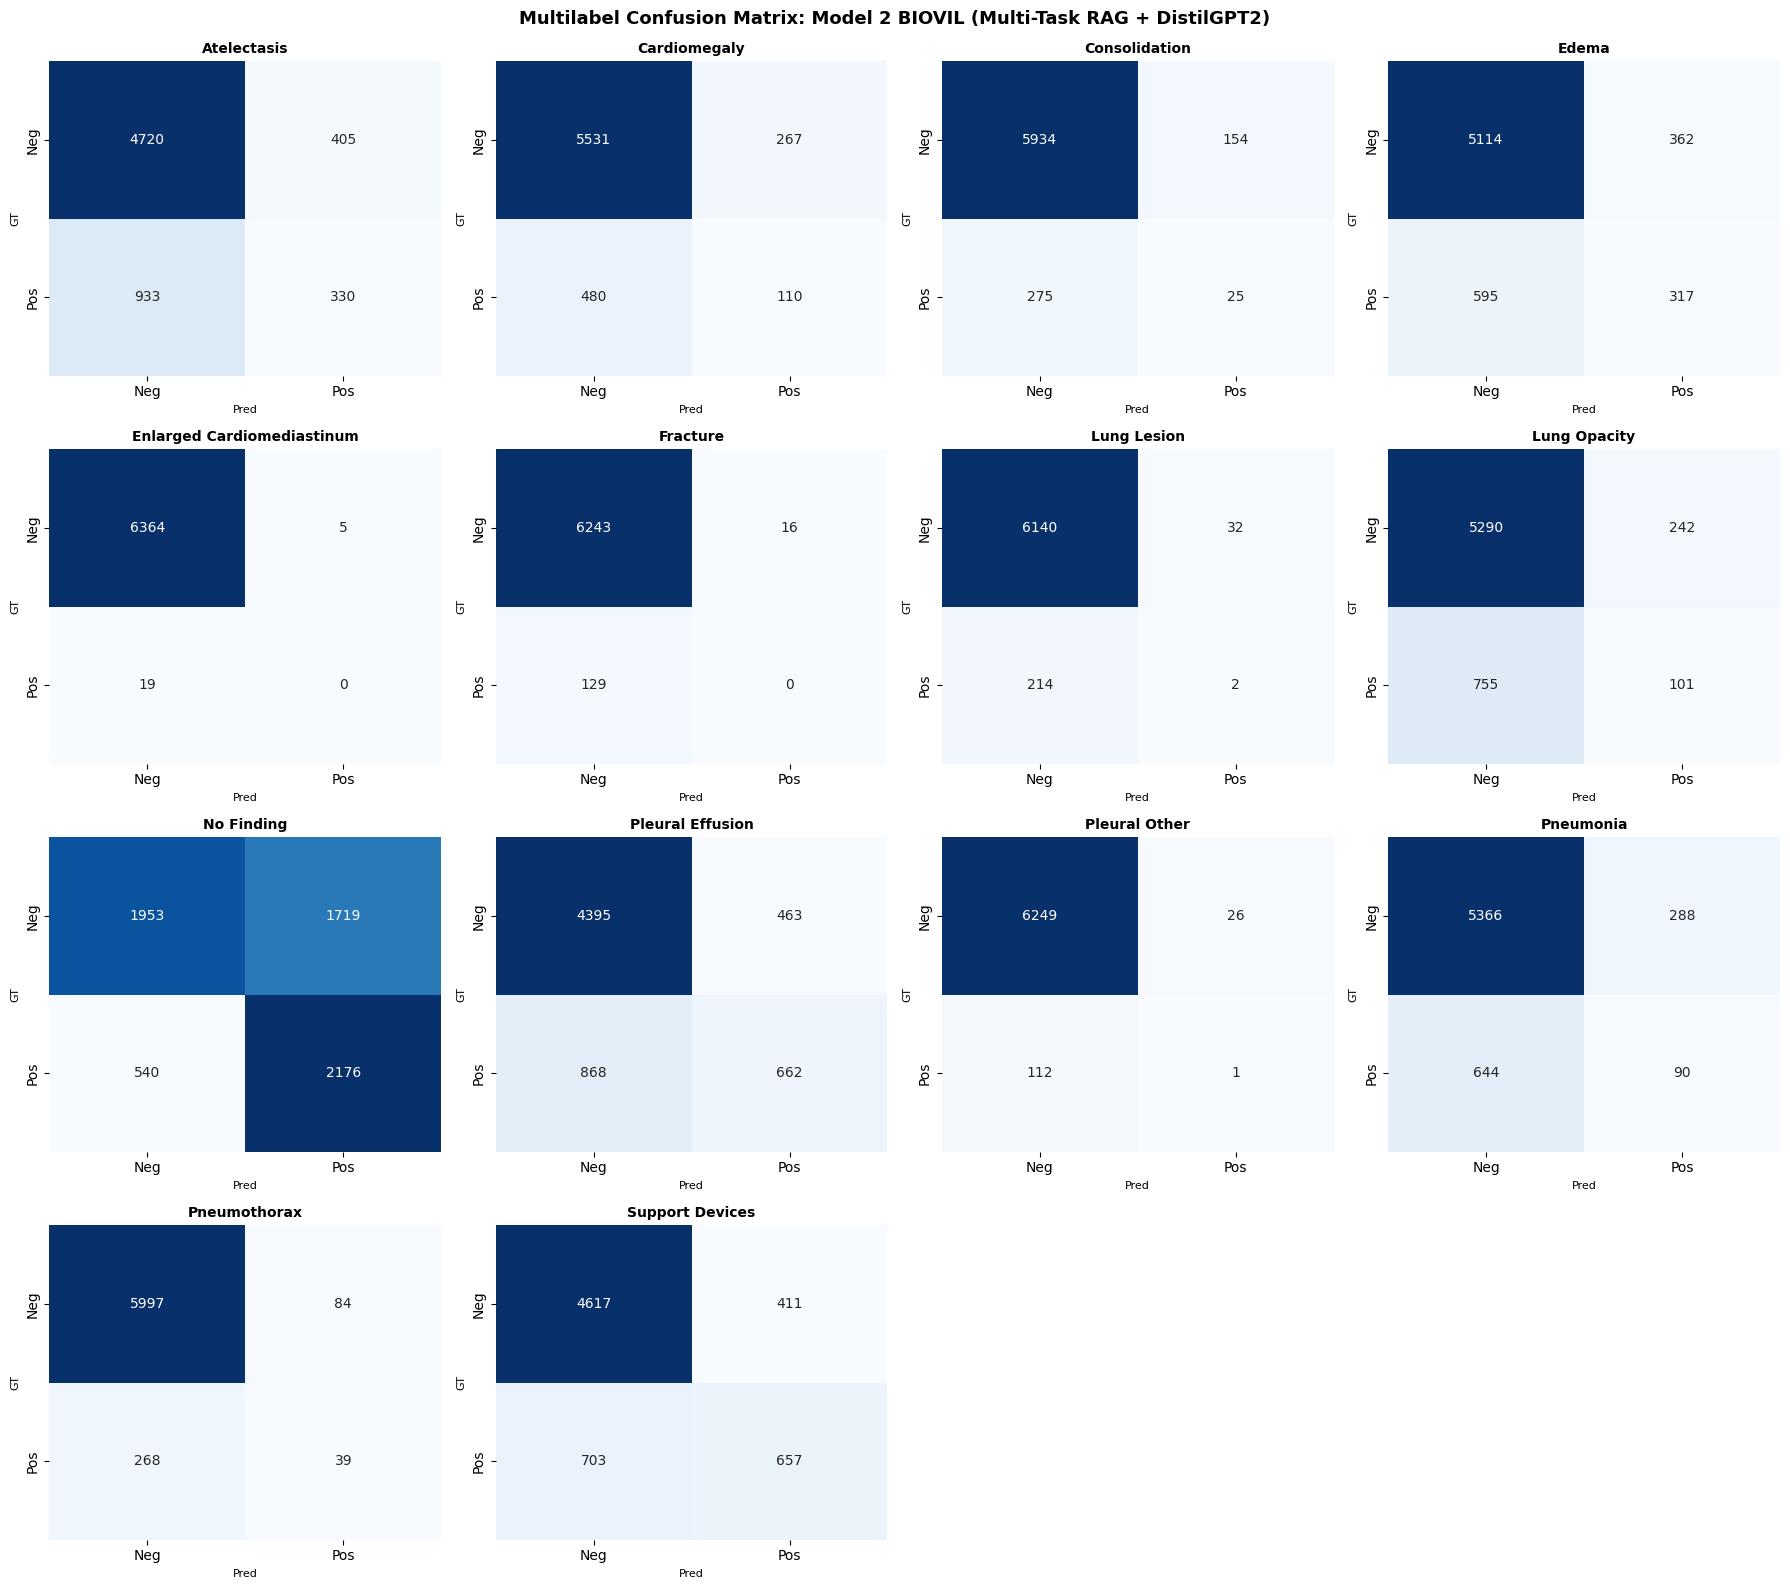

Model Evaluation artifacts saved successfully to /kaggle/working/


In [4]:
# -------------------------------------------------------------------------
# 3. High-Speed Benchmark Evaluation Cell (6,388 Test Samples) (Memmap Speedup)
# -------------------------------------------------------------------------
import os, json, torch, pandas as pd, numpy as np, nltk, re
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from nltk.util import ngrams
from rouge_score import rouge_scorer
from tqdm import tqdm
from sklearn.metrics import f1_score, precision_score, recall_score, multilabel_confusion_matrix, roc_auc_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if 'tokenizer' not in locals():
    from transformers import AutoTokenizer
    tokenizer = AutoTokenizer.from_pretrained("distilgpt2")
    special_tokens = {"bos_token": "<bos>", "eos_token": "<eos>", "pad_token": "<pad>", "additional_special_tokens": ["<rag>", "</rag>", "<report>", "</report>"]}
    tokenizer.add_special_tokens(special_tokens)

vocab_size = len(tokenizer)
pad_id = tokenizer.pad_token_id
eos_id = tokenizer.eos_token_id

checkpoint_path = f"/kaggle/working/model2_{"biovil"}_best.pt"
if not os.path.exists(checkpoint_path):
    checkpoint_path = f"/kaggle/working/model2_{"biovil"}_resumable.pt"
    if not os.path.exists(checkpoint_path):
        raise FileNotFoundError(f"Model checkpoint not found. Ensure training cell execution.")

# Complete standalone definition of model class to prevent standalone session NameErrors
import torch.nn as nn
from transformers import GPT2LMHeadModel

class MultiTaskRAGAdaptiveDistilGPT2(nn.Module):
    def __init__(self, vocab_size, visual_dim, num_patches, num_classes=14, pad_token_id=0):
        super().__init__()
        self.pad_token_id = pad_token_id
        self.num_patches = num_patches
        
        self.classifier_head = nn.Sequential(
            nn.Linear(visual_dim, 256),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(256, num_classes)
        )
            
        self.visual_projection = nn.Sequential(
            nn.Linear(visual_dim, 768),
            nn.GELU(),
            nn.Linear(768, 768),
            nn.LayerNorm(768)
        )
        
        self.decoder = GPT2LMHeadModel.from_pretrained("distilgpt2")
        self.decoder.resize_token_embeddings(vocab_size)

    def forward(self, spatial_tokens, mean_features, input_ids):
        batch_size, seq_len = input_ids.shape
        cls_logits = self.classifier_head(mean_features)
        visual_embeds = self.visual_projection(spatial_tokens)
        text_embeds = self.decoder.transformer.wte(input_ids)
        inputs_embeds = torch.cat([visual_embeds, text_embeds], dim=1)
        
        vis_pos_ids = torch.arange(0, self.num_patches, dtype=torch.long, device=input_ids.device).unsqueeze(0).repeat(batch_size, 1)
        text_pos_ids = torch.arange(0, seq_len, dtype=torch.long, device=input_ids.device).unsqueeze(0).repeat(batch_size, 1)
        position_ids = torch.cat([vis_pos_ids, text_pos_ids], dim=1)
        
        vis_attn = torch.ones((batch_size, self.num_patches), device=input_ids.device)
        text_attn = (input_ids != self.pad_token_id).float()
        attention_mask = torch.cat([vis_attn, text_attn], dim=1)
        
        outputs = self.decoder(inputs_embeds=inputs_embeds, position_ids=position_ids, attention_mask=attention_mask)
        logits = outputs.logits
        text_logits = logits[:, self.num_patches:-1, :].contiguous()
        return text_logits, cls_logits

    @torch.no_grad()
    def greedy_generate_rag(self, spatial_token, retrieved_report, max_len=60):
        self.eval()
        if spatial_token.dim() == 2:
            spatial_token = spatial_token.unsqueeze(0)
            
        visual_embeds = self.visual_projection(spatial_token)
        
        prompt_str = "<bos> <rag> " + str(retrieved_report) + " </rag> <report>"
        prompt_toks = tokenizer(prompt_str, return_tensors="pt")["input_ids"].to(spatial_token.device)
        prompt_len = prompt_toks.shape[1]
        
        text_embeds = self.decoder.transformer.wte(prompt_toks)
        inputs_embeds = torch.cat([visual_embeds, text_embeds], dim=1)
        
        vis_pos_ids = torch.arange(0, self.num_patches, dtype=torch.long, device=spatial_token.device).unsqueeze(0)
        prompt_pos_ids = torch.arange(0, prompt_len, dtype=torch.long, device=spatial_token.device).unsqueeze(0)
        pos_ids = torch.cat([vis_pos_ids, prompt_pos_ids], dim=1)
        
        outputs = self.decoder(inputs_embeds=inputs_embeds, position_ids=pos_ids, use_cache=True)
        next_token_logits = outputs.logits[:, -1, :]
        next_id = next_token_logits.argmax(-1).item()
        past_key_values = outputs.past_key_values
        
        generated_ids = []
        if next_id != eos_id:
            generated_ids.append(next_id)
            current_ids = torch.tensor([[next_id]], device=spatial_token.device)
        else:
            current_ids = torch.tensor([[eos_id]], device=spatial_token.device)
            
        for step in range(max_len):
            if next_id == eos_id:
                break
                
            curr_pos_id = torch.tensor([[prompt_len + step]], dtype=torch.long, device=spatial_token.device)
            outputs = self.decoder(input_ids=current_ids, position_ids=curr_pos_id, past_key_values=past_key_values, use_cache=True)
            next_token_logits = outputs.logits[:, -1, :]
            next_id = next_token_logits.argmax(-1).item()
            past_key_values = outputs.past_key_values
            
            if next_id == eos_id:
                break
            generated_ids.append(next_id)
            current_ids = torch.tensor([[next_id]], device=spatial_token.device)
            
        return generated_ids

# Re-instantiate model if running cell 4 independently
if 'model' not in locals():
    print("Re-instantiating model for standalone evaluation...")
    v_dim = 768 if "biovil" == "cxformer" else 2048
    n_patches = 128 if "biovil" == "cxformer" else 49
    model = MultiTaskRAGAdaptiveDistilGPT2(vocab_size=vocab_size, visual_dim=v_dim, num_patches=n_patches, pad_token_id=pad_id).to(device)

checkpoint_data = torch.load(checkpoint_path, map_location=device)
state_dict = checkpoint_data['model_state'] if 'model_state' in checkpoint_data else checkpoint_data
model.load_state_dict(state_dict)
model.eval()
print(f"Model 2 ({"biovil".upper()}) Checkpoint loaded successfully.")

# Setup memmap array for fast test features reading
num_patches = 128 if "biovil" == "cxformer" else 49
visual_dim = 768 if "biovil" == "cxformer" else 2048
test_spatial_path = f"/kaggle/working/test_spatial.dat"

if os.path.exists(test_spatial_path):
    print("Pre-calculated test spatial features found. Loading from fast memmap...")
    test_spatial_memmap = np.memmap(test_spatial_path, dtype='float16', mode='r', shape=(len(test_df), num_patches, visual_dim))
else:
    print("Pre-calculated test spatial features not found. Running on-the-fly extractor fallback...")
    test_spatial_memmap = None
    # Initialize visual model fallback if running independently
    if "biovil" == "biovil":
        from health_multimodal.image.utils import get_image_inference, ImageModelType
        image_inference = get_image_inference(ImageModelType.BIOVIL)
        feature_extractor = image_inference.model.encoder.to(device)
        feature_extractor.eval()
        biovil_transform = image_inference.transform
        def transform_fn(img): return biovil_transform(img).clone()
        class BioViLExtractor(nn.Module):
            def __init__(self, raw_model, target_patches=49):
                super().__init__()
                self.model = raw_model
                self.target_patches = target_patches
                self.pool = nn.AdaptiveAvgPool1d(target_patches)
            def forward(self, x):
                feats, _ = self.model(x, return_patch_embeddings=True)
                spatial_tokens = feats.flatten(2).permute(0, 2, 1)
                mean_features = spatial_tokens.mean(dim=1)
                if spatial_tokens.shape[1] != self.target_patches:
                    spatial_tokens = self.pool(spatial_tokens.permute(0, 2, 1)).permute(0, 2, 1)
                return spatial_tokens, mean_features
        feature_extractor_wrapper = BioViLExtractor(feature_extractor, target_patches=49)
    else:
        from transformers import AutoImageProcessor, AutoModel
        processor = AutoImageProcessor.from_pretrained("m42-health/CXformer-base", trust_remote_code=True)
        encoder_model = AutoModel.from_pretrained("m42-health/CXformer-base", trust_remote_code=True).to(device)
        encoder_model.eval()
        def transform_fn(img): return processor(images=img, return_tensors="pt")["pixel_values"].squeeze(0).clone()
        class CXformerExtractor(nn.Module):
            def __init__(self, raw_model, target_patches=128):
                super().__init__()
                self.model = raw_model
                self.target_patches = target_patches
                self.pool = nn.AdaptiveAvgPool1d(target_patches)
            def forward(self, x):
                outputs = self.model(pixel_values=x)
                all_tokens = outputs.last_hidden_state[:, 1:, :]
                mean_features = outputs.last_hidden_state[:, 0, :]
                if all_tokens.shape[1] != self.target_patches:
                    all_tokens = self.pool(all_tokens.permute(0, 2, 1)).permute(0, 2, 1)
                return all_tokens, mean_features
        feature_extractor_wrapper = CXformerExtractor(encoder_model, target_patches=128)

smooth = SmoothingFunction().method1
rouge_evaluator = rouge_scorer.RougeScorer(['rouge1', 'rouge2', 'rougeL'], use_stemmer=True)

clinical_keywords = {
    'Atelectasis': ['atelectasis', 'atelectatic', 'collapse', 'volume loss'],
    'Cardiomegaly': ['cardiomegaly', 'enlarged heart', 'enlarged cardiac', 'cardiac enlargement'],
    'Consolidation': ['consolidation', 'airspace disease', 'airspace opacity'],
    'Edema': ['edema', 'vascular congestion', 'fluid overload', 'interstitial edema'],
    'Enlarged Cardiomediastinum': ['widened mediastinum', 'mediastinal widening', 'cardiomediastinum'],
    'Fracture': ['fracture', 'fractured', 'broken rib', 'healing fracture'],
    'Lung Lesion': ['lung lesion', 'nodule', 'mass', 'nodular opacity'],
    'Lung Opacity': ['opacity', 'opacities', 'infiltrate', 'clouding'],
    'No Finding': ['normal', 'clear', 'unremarkable', 'no acute', 'negative'],
    'Pleural Effusion': ['pleural effusion', 'effusion', 'blunting', 'fluid in pleural'],
    'Pleural Other': ['pleural thickening', 'fibrosis', 'calcification'],
    'Pneumonia': ['pneumonia', 'infectious process', 'bronchopneumonia'],
    'Pneumothorax': ['pneumothorax', 'air in pleural', 'apical pneumothorax'],
    'Support Devices': ['tube', 'catheter', 'pacemaker', 'pacer', 'line', 'picc', 'stent']
}

negation_prefix_pattern = re.compile(r"\b(no|without|free of|negative for|absence of|denies|cleared of)\b\s*([\w\s]{0,35})$", re.IGNORECASE)
negation_suffix_pattern = re.compile(r"^([\w\s]{0,35})\s*\b(ruled out|is absent|resolved|excluded|unlikely|is not seen|not identified|has resolved|is clear)\b", re.IGNORECASE)

def detect_clinical_presence(text, keywords):
    text_lower = text.lower()
    for kw in keywords:
        matches = [m.start() for m in re.finditer(re.escape(kw), text_lower)]
        for match_idx in matches:
            prefix_window = text_lower[max(0, match_idx - 35):match_idx]
            suffix_window = text_lower[match_idx + len(kw):min(len(text_lower), match_idx + len(kw) + 35)]
            if not negation_prefix_pattern.search(prefix_window) and not negation_suffix_pattern.search(suffix_window):
                return 1
    return 0

print("Generating reports on " + str(len(test_df)) + " unseen test cases using RAG FAISS & KV Cache...")

results = []
bleu1_scores, bleu2_scores, bleu3_scores, bleu4_scores = [], [], [], []
rouge1_scores, rouge2_scores, rougeL_scores = [], [], []
distinct2_scores = []
gt_pathology_matrix = []
pred_pathology_matrix = []

with torch.no_grad():
    for idx in tqdm(range(len(test_df)), desc="Evaluating Model 2 Test Set"):
        row = test_df.iloc[idx]
        retrieved_r = test_df.iloc[idx]["retrieved_report"]
        
        # Read pre-calculated features if available, otherwise extract on-the-fly
        if test_spatial_memmap is not None:
            spatial_t = torch.tensor(test_spatial_memmap[idx], dtype=torch.float32).unsqueeze(0).to(device)
        else:
            try:
                img = Image.open(row['image_path']).convert('RGB' if "biovil" == 'cxformer' else 'L')
                image_tensor = transform_fn(img).unsqueeze(0).to(device)
            except Exception:
                image_tensor = torch.zeros((1, 3 if "biovil" == 'cxformer' else 1, 224, 224), device=device)
            spatial_t, _ = feature_extractor_wrapper(image_tensor)
            
        gen_tokens = model.greedy_generate_rag(spatial_t.squeeze(0), retrieved_r, max_len=60)
        pred_text = tokenizer.decode(gen_tokens, skip_special_tokens=True).strip()
        gt_text = str(row['report']).strip()
        
        ref_tokens = [nltk.word_tokenize(gt_text.lower())] if gt_text else [[""]]
        hyp_tokens = nltk.word_tokenize(pred_text.lower()) if pred_text else [""]
        
        b1 = sentence_bleu(ref_tokens, hyp_tokens, weights=(1, 0, 0, 0), smoothing_function=smooth)
        b2 = sentence_bleu(ref_tokens, hyp_tokens, weights=(0.5, 0.5, 0, 0), smoothing_function=smooth)
        b3 = sentence_bleu(ref_tokens, hyp_tokens, weights=(0.33, 0.33, 0.33, 0), smoothing_function=smooth)
        b4 = sentence_bleu(ref_tokens, hyp_tokens, weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=smooth)
        
        rouge_res = rouge_evaluator.score(gt_text, pred_text)
        r1 = rouge_res['rouge1'].fmeasure
        r2 = rouge_res['rouge2'].fmeasure
        rL = rouge_res['rougeL'].fmeasure
        
        bleu1_scores.append(b1)
        bleu2_scores.append(b2)
        bleu3_scores.append(b3)
        bleu4_scores.append(b4)
        rouge1_scores.append(r1)
        rouge2_scores.append(r2)
        rougeL_scores.append(rL)
        
        if len(hyp_tokens) >= 2:
            bigrams = list(ngrams(hyp_tokens, 2))
            distinct2_scores.append(len(set(bigrams)) / len(bigrams))
        
        gt_row_labels = [detect_clinical_presence(gt_text, kws) for kws in clinical_keywords.values()]
        pred_row_labels = [detect_clinical_presence(pred_text, kws) for kws in clinical_keywords.values()]
        
        gt_pathology_matrix.append(gt_row_labels)
        pred_pathology_matrix.append(pred_row_labels)
        
        results.append({
            "dicom_id": row["dicom_id"],
            "study_id": row["study_id"],
            "ground_truth": gt_text,
            "prediction": pred_text,
            "retrieved_exemplar": retrieved_r,
            "bleu1": round(b1, 4),
            "bleu4": round(b4, 4),
            "rougeL": round(rL, 4)
        })

gt_matrix = np.array(gt_pathology_matrix)
pred_matrix = np.array(pred_pathology_matrix)

pathology_names = list(clinical_keywords.keys())
chexpert_gt_counts = np.array([test_df[col].sum() for col in pathology_names])
core_indices = [i for i, cnt in enumerate(chexpert_gt_counts) if cnt >= 100]

summary_metrics = {
    "Model": f"Model 2 {"biovil".upper()} (Multi-Task RAG + DistilGPT2)",
    "Test_Samples": len(results),
    "BLEU-1": round(float(np.mean(bleu1_scores)), 4),
    "BLEU-2": round(float(np.mean(bleu2_scores)), 4),
    "BLEU-3": round(float(np.mean(bleu3_scores)), 4),
    "BLEU-4": round(float(np.mean(bleu4_scores)), 4),
    "ROUGE-1": round(float(np.mean(rouge1_scores)), 4),
    "ROUGE-2": round(float(np.mean(rouge2_scores)), 4),
    "ROUGE-L": round(float(np.mean(rougeL_scores)), 4),
    "Distinct-2": round(float(np.mean(distinct2_scores)), 4) if distinct2_scores else 0.0,
    "Clinical_Macro_F1_All14": round(float(f1_score(gt_matrix, pred_matrix, average='macro', zero_division=0)), 4),
    "Clinical_Macro_F1_Core10": round(float(f1_score(gt_matrix[:, core_indices], pred_matrix[:, core_indices], average='macro', zero_division=0)), 4),
    "Clinical_Micro_F1": round(float(f1_score(gt_matrix, pred_matrix, average='micro', zero_division=0)), 4),
    "Clinical_Micro_Precision": round(float(precision_score(gt_matrix, pred_matrix, average='micro', zero_division=0)), 4),
    "Clinical_Micro_Recall": round(float(recall_score(gt_matrix, pred_matrix, average='micro', zero_division=0)), 4)
}

print("")
print("=" * 80)
print(f"OVERALL BENCHMARK: Model 2 {"biovil".upper()} (Multi-Task RAG + DistilGPT2)")
print("=" * 80)
for k, v in summary_metrics.items():
    if k not in ["Model", "Test_Samples"]:
        print(f"{k:<30} | {v}")
print("=" * 80)

mcm = multilabel_confusion_matrix(gt_matrix, pred_matrix)
pathology_stats = []

print("")
print("=" * 110)
print(f"PER-PATHOLOGY CLINICAL BREAKDOWN: Model 2 {"biovil".upper()} (Proposal N >= 150 Threshold Flagging)")
print("=" * 110)
for i, name in enumerate(pathology_names):
    tn, fp, fn, tp = mcm[i].ravel()
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec  = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1   = 2 * prec * rec / (prec + rec) if (prec + rec) > 0 else 0.0
    official_chex_count = int(test_df[name].sum())
    warning_flag = "[!] Low Sample (N < 150)" if official_chex_count < 150 else "OK"
    pathology_stats.append({
        "Pathology": name, "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn),
        "Precision": round(prec, 4), "Recall": round(rec, 4), "F1_Score": round(f1, 4),
        "Official_CheXpert_Count": official_chex_count, "Sample_Status": warning_flag
    })
    print(f"{name:<26} | {tp:<5} | {fp:<5} | {fn:<5} | {tn:<5} | {prec:<7.4f} | {rec:<7.4f} | {f1:<7.4f} | {warning_flag}")

fig, axes = plt.subplots(4, 4, figsize=(18, 16))
axes = axes.flatten()
for i, name in enumerate(pathology_names):
    sns.heatmap(mcm[i], annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[i], xticklabels=["Neg", "Pos"], yticklabels=["Neg", "Pos"])
    axes[i].set_title(name, fontsize=10, fontweight='bold')
    axes[i].set_ylabel("GT", fontsize=8)
    axes[i].set_xlabel("Pred", fontsize=8)
for j in range(len(pathology_names), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle(f"Multilabel Confusion Matrix: Model 2 {"biovil".upper()} (Multi-Task RAG + DistilGPT2)", fontsize=13, fontweight='bold', y=0.99)
plt.tight_layout()
plt.savefig(f"/kaggle/working/model2_{"biovil"}_confusion_matrices.png", dpi=300, bbox_inches='tight')
plt.show()

pd.DataFrame(results).to_csv(f"/kaggle/working/model2_{"biovil"}_test_predictions.csv", index=False)
pd.DataFrame(pathology_stats).to_csv(f"/kaggle/working/model2_{"biovil"}_pathology_breakdown.csv", index=False)
with open(f"/kaggle/working/model2_{"biovil"}_test_metrics.json", "w") as f:
    json.dump(summary_metrics, f, indent=2)

print("Model Evaluation artifacts saved successfully to /kaggle/working/")
